# Deep Armocromia E5 — FaRL16 Paper Replication (12 Season–Subtype Classes)

Notebook ini dibuat untuk mereplikasi **se-dekat mungkin** eksperimen 12-class pada paper:

> Stacchio, L., Paolanti, M., Spigarelli, F., & Frontoni, E.  
> *Deep Armocromia: A Novel Dataset for Face Seasonal Color Analysis and Classification.*  
> ECCV 2024 Workshops / Springer, DOI: `10.1007/978-3-031-91569-7_22`.

## Target benchmark paper — 12 Season + Sub-Type

| Model | Accuracy | Precision | Recall | F1 | Top-3 |
|---|---:|---:|---:|---:|---:|
| **FaRL16** | **0.318** | **0.317** | **0.318** | **0.310** | **0.663** |
| FaRL64 | 0.313 | 0.307 | 0.313 | 0.308 | 0.651 |
| ResNeXt50 | 0.281 | 0.262 | 0.281 | 0.250 | 0.614 |

## Metode yang direplikasi dari paper

- Input: **RGB-masked (RGB-M)**.
- Official benchmark: sekitar **4k training / 900 testing**.
- Tidak ada overlap wajah antara train dan test.
- Backbone: **FaRL16** pretrained pada LAION-Face.
- **Backbone dibekukan**; hanya classifier yang dilatih.
- Classifier:
  - FC: `D → D/2`
  - ReLU
  - Dropout `p=0.5`
  - FC: `D/2 → 12`
- Input akhir: `3×224×224`.
- Augmentation:
  - random crop
  - horizontal flip `p=0.5`
  - brightness jitter `0.4`
  - contrast jitter `0.2`
  - saturation jitter `0.2`
  - random sharpness factor `2`, `p=0.2`
- Training: **50 epochs tetap**.
- AdamW:
  - `lr=1e-3`
  - `weight_decay=1e-5`
- Cosine Annealing with Warm Restarts:
  - restart setiap `10`
  - minimum LR `1e-5`
- Batch size `64`.

## Perbedaan implementasi yang perlu dicatat

Paper menyebut **random crop** tetapi tidak menjelaskan ukuran intermediate sebelum crop.  
Notebook ini memakai:

`Resize(256×256) → RandomCrop(224×224)`

sebagai implementasi operasional yang eksplisit.

Untuk normalisasi, notebook memakai **CLIP/FaRL normalization** dari struktur resmi FaRL/CLIP. Nilai normalisasi ini berasal dari implementasi CLIP/FaRL, bukan dinyatakan eksplisit pada paper Deep Armocromia.

## Sebelum Run All di Kaggle

1. Attach private dataset **Deep Armocromia**.
2. Buat Kaggle Secret:
   - Name: `DEEP_ARMO_PASSWORD`
   - Value: password resmi `RGB-M.zip`
3. Settings → Accelerator → **GPU T4**.
4. **Internet = ON** untuk instalasi OpenAI CLIP dan auto-download checkpoint FaRL16.

Alternatif jika Internet dimatikan:
- attach file `FaRL-Base-Patch16-LAIONFace20M-ep16.pth` sebagai Kaggle Input;
- tetapi package OpenAI CLIP juga harus sudah tersedia.

Notebook ini **tidak menggunakan early stopping**, karena paper melatih model selama 50 epoch tetap.

## 0. Konfigurasi eksperimen

In [1]:
# ============================================================
# 0. EXPERIMENT CONFIG
# ============================================================

EXPERIMENT_ID = "E5_FARL16_PAPER_REPLICATION"
EXPERIMENT_NAME = "FaRL16 frozen backbone + paper classifier"

SEED = 42
IMG_SIZE = 224
PRE_CROP_SIZE = 256

NUM_CLASSES = 12
BATCH_SIZE = 64
NUM_WORKERS = 4

EPOCHS = 50

LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-5

WARM_RESTART_T0 = 10
MIN_LR = 1e-5

DROPOUT = 0.5

FARL_FILENAME = "FaRL-Base-Patch16-LAIONFace20M-ep16.pth"
FARL_URL = (
    "https://github.com/FacePerceiver/FaRL/releases/download/"
    "pretrained_weights/FaRL-Base-Patch16-LAIONFace20M-ep16.pth"
)

# Paper-reported benchmark
PAPER_FARL16 = {
    "accuracy": 0.318,
    "precision": 0.317,
    "recall": 0.318,
    "f1": 0.310,
    "top3_accuracy": 0.663,
}

# Best EfficientNet result previously observed in this project
PROJECT_EFFICIENTNET_BEST = {
    "accuracy": 0.3059,
    "macro_recall": 0.2809,
    "macro_f1": 0.2700,
    "top3_accuracy": 0.6349,
}

print(EXPERIMENT_ID)
print(EXPERIMENT_NAME)

E5_FARL16_PAPER_REPLICATION
FaRL16 frozen backbone + paper classifier


## 1. Imports & reproducibility

In [2]:
# ============================================================
# 1. IMPORTS & REPRODUCIBILITY
# ============================================================

import os
import sys
import json
import time
import math
import random
import shutil
import hashlib
import subprocess
import warnings
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageFile

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

ImageFile.LOAD_TRUNCATED_IMAGES = False

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Python :", sys.version.split()[0])
print("Torch  :", torch.__version__)
print("CUDA   :", torch.cuda.is_available())

Python : 3.13.15
Torch  : 2.11.0+cu128
CUDA   : True


## 2. GPU check

In [3]:
# ============================================================
# 2. GPU CHECK
# ============================================================

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("Device:", DEVICE)

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )
    print(
        "VRAM:",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / (1024 ** 3),
            2,
        ),
        "GiB",
    )

assert DEVICE.type == "cuda", (
    "GPU belum aktif. "
    "Kaggle Settings → Accelerator → GPU T4."
)

Device: cuda
GPU: Tesla T4
VRAM: 14.56 GiB


## 3. Deteksi Deep Armocromia

Notebook mendukung dua kondisi:

1. Dataset private masih memiliki `RGB-M.zip` terenkripsi.
2. Dataset private sudah memiliki folder `RGB-M/` hasil ekstraksi.

Untuk encrypted source, password dibaca dari Kaggle Secret `DEEP_ARMO_PASSWORD`.

In [4]:
# ============================================================
# 3. DETECT DEEP ARMOCROMIA DATASET
# ============================================================

KAGGLE_INPUT = Path("/kaggle/input")
WORK_PREPARED_ROOT = Path(
    "/kaggle/working/deep_armocromia_prepared"
)

assert KAGGLE_INPUT.exists(), (
    "/kaggle/input tidak ditemukan."
)

annotation_candidates = list(
    KAGGLE_INPUT.rglob("annotations.csv")
)

prepared_matches = []
source_matches = []

for ann in annotation_candidates:
    root = ann.parent

    if (root / "RGB-M").is_dir():
        prepared_matches.append(
            (root, ann)
        )

    if (root / "RGB-M.zip").is_file():
        source_matches.append(
            (
                root,
                ann,
                root / "RGB-M.zip",
            )
        )

if prepared_matches:
    MODE = "PREPARED_INPUT"
    DATA_ROOT, ANNOTATION_PATH = (
        prepared_matches[0]
    )
    RGBM_ZIP = None

elif source_matches:
    MODE = "ENCRYPTED_SOURCE"
    (
        SOURCE_ROOT,
        ANNOTATION_PATH,
        RGBM_ZIP,
    ) = source_matches[0]

    DATA_ROOT = WORK_PREPARED_ROOT

else:
    raise FileNotFoundError(
        "Tidak menemukan annotations.csv "
        "+ RGB-M/ atau RGB-M.zip. "
        "Attach private dataset Deep Armocromia."
    )

print("MODE       :", MODE)
print("ANNOTATION :", ANNOTATION_PATH)
print("DATA ROOT  :", DATA_ROOT)

MODE       : ENCRYPTED_SOURCE
ANNOTATION : /kaggle/input/datasets/fatihitsbatulhaq/deep-armocromia/Deep Armocromia/release/annotations.csv
DATA ROOT  : /kaggle/working/deep_armocromia_prepared


## 4. Load annotations & 12-class labels

In [5]:
# ============================================================
# 4. LOAD ANNOTATIONS
# ============================================================

df = pd.read_csv(
    ANNOTATION_PATH
)

SEASON_COL = "class"
SUBCLASS_COL = "sub_class"
PARTITION_COL = "partition"
MASKED_PATH_COL = "path_rgb_masked"

required_cols = [
    SEASON_COL,
    SUBCLASS_COL,
    PARTITION_COL,
    MASKED_PATH_COL,
    "celeba",
]

missing_cols = [
    c for c in required_cols
    if c not in df.columns
]

assert not missing_cols, (
    f"Kolom wajib hilang: {missing_cols}"
)

for col in [
    SEASON_COL,
    SUBCLASS_COL,
    PARTITION_COL,
]:
    df[col] = (
        df[col]
        .astype(str)
        .str.strip()
        .str.lower()
    )

df["joint_label"] = (
    df[SEASON_COL]
    + "_"
    + df[SUBCLASS_COL]
)

if df["celeba"].dtype != bool:
    df["celeba"] = (
        df["celeba"]
        .astype(str)
        .str.strip()
        .str.lower()
        .map({
            "true": True,
            "1": True,
            "false": False,
            "0": False,
        })
    )

assert df["celeba"].notna().all()

EXPECTED_IMAGES = len(df)

print("Rows          :", len(df))
print("Seasons       :", df[SEASON_COL].nunique())
print("Subtype names :", df[SUBCLASS_COL].nunique())
print("Joint classes :", df["joint_label"].nunique())
print("Missing       :", int(
    df[required_cols]
    .isna()
    .sum()
    .sum()
))
print("Duplicate row :", int(
    df.duplicated().sum()
))

assert df["joint_label"].nunique() == 12

Rows          : 4920
Seasons       : 4
Subtype names : 6
Joint classes : 12
Missing       : 0
Duplicate row : 0


## 5. Extract RGB-M dengan Kaggle Secret

In [6]:
# ============================================================
# 5. EXTRACT RGB-M USING KAGGLE SECRET
# ============================================================

IMAGE_EXTENSIONS = {
    ".png",
    ".jpg",
    ".jpeg",
}

def count_images(root):
    if not root.exists():
        return 0

    return sum(
        1
        for p in root.rglob("*")
        if p.is_file()
        and p.suffix.lower()
        in IMAGE_EXTENSIONS
    )

if MODE == "PREPARED_INPUT":
    RGBM_ROOT = (
        DATA_ROOT / "RGB-M"
    )

    print(
        "✅ Prepared RGB-M digunakan."
    )

else:
    WORK_PREPARED_ROOT.mkdir(
        parents=True,
        exist_ok=True,
    )

    RGBM_ROOT = (
        WORK_PREPARED_ROOT
        / "RGB-M"
    )

    current_count = count_images(
        RGBM_ROOT
    )

    print(
        "Current extracted RGB-M:",
        current_count,
        "/",
        EXPECTED_IMAGES,
    )

    if current_count != EXPECTED_IMAGES:
        from kaggle_secrets import (
            UserSecretsClient
        )

        try:
            PASSWORD = (
                UserSecretsClient()
                .get_secret(
                    "DEEP_ARMO_PASSWORD"
                )
            )
        except Exception as e:
            raise RuntimeError(
                "Kaggle Secret "
                "'DEEP_ARMO_PASSWORD' "
                "belum tersedia atau "
                "belum diaktifkan."
            ) from e

        if not PASSWORD:
            raise RuntimeError(
                "DEEP_ARMO_PASSWORD kosong."
            )

        print(
            "🔐 Kaggle Secret berhasil dibaca."
        )
        print("Extracting RGB-M...")

        unzip_path = shutil.which(
            "unzip"
        )

        if unzip_path:
            result = subprocess.run(
                [
                    unzip_path,
                    "-n",
                    "-P",
                    PASSWORD,
                    str(RGBM_ZIP),
                    "-d",
                    str(
                        WORK_PREPARED_ROOT
                    ),
                ],
                stdout=subprocess.DEVNULL,
                stderr=subprocess.PIPE,
                text=True,
            )

            if result.returncode not in (
                0,
                1,
            ):
                raise RuntimeError(
                    result.stderr[-3000:]
                )

        else:
            import zipfile

            with zipfile.ZipFile(
                RGBM_ZIP,
                "r",
            ) as z:
                z.extractall(
                    WORK_PREPARED_ROOT,
                    pwd=PASSWORD.encode(
                        "utf-8"
                    ),
                )

        del PASSWORD

    final_count = count_images(
        RGBM_ROOT
    )

    assert (
        final_count
        == EXPECTED_IMAGES
    ), (
        f"Expected {EXPECTED_IMAGES}, "
        f"found {final_count} RGB-M images."
    )

    prepared_annotation = (
        WORK_PREPARED_ROOT
        / "annotations.csv"
    )

    if not (
        prepared_annotation.exists()
    ):
        shutil.copy2(
            ANNOTATION_PATH,
            prepared_annotation,
        )

    DATA_ROOT = (
        WORK_PREPARED_ROOT
    )
    ANNOTATION_PATH = (
        prepared_annotation
    )

print(
    "RGB-M image count:",
    count_images(RGBM_ROOT)
)

assert (
    count_images(RGBM_ROOT)
    == EXPECTED_IMAGES
)

Current extracted RGB-M: 0 / 4920
🔐 Kaggle Secret berhasil dibaca.
Extracting RGB-M...
RGB-M image count: 4920


## 6. EDA — label, source, official partition

Paper menyatakan dataset berjumlah 4,920 gambar, dengan benchmark sekitar 80/20.  
Notebook menggunakan **partition resmi dari `annotations.csv`** dan tidak membuat validation split untuk E5, karena paper melatih 50 epoch tetap.

In [7]:
# ============================================================
# 6. LABEL / SOURCE / PARTITION EDA
# ============================================================

print("Season distribution")
display(
    df[SEASON_COL]
    .value_counts()
    .sort_index()
    .to_frame("count")
)

print("\n12 joint classes")
joint_counts = (
    df["joint_label"]
    .value_counts()
    .sort_index()
)

display(
    joint_counts.to_frame(
        "count"
    )
)

imbalance_ratio = (
    joint_counts.max()
    / joint_counts.min()
)

print(
    "\nImbalance ratio:",
    round(
        float(imbalance_ratio),
        3,
    )
)

print("\nOfficial partition")
display(
    df[PARTITION_COL]
    .value_counts()
    .to_frame("count")
)

print(
    "\nSource (CelebA) by partition"
)

display(
    pd.crosstab(
        df[PARTITION_COL],
        df["celeba"],
    )
)

print(
    "\nSource percentage"
)

display(
    (
        pd.crosstab(
            df[PARTITION_COL],
            df["celeba"],
            normalize="index",
        )
        * 100
    ).round(2)
)

Season distribution


,count
class,
autunno,1305
estate,1129
inverno,1305
primavera,1181



12 joint classes


,count
joint_label,
autunno_deep,557
autunno_soft,391
autunno_warm,357
estate_cool,329
estate_light,382
estate_soft,418
inverno_bright,329
inverno_cool,434
inverno_deep,542



Imbalance ratio: 1.693

Official partition


,count
partition,
train,4008
test,912



Source (CelebA) by partition


celeba,False,True
partition,,
test,0,912
train,1939,2069



Source percentage


celeba,False,True
partition,,
test,0.00,100.00
train,48.38,51.62


## 7. Resolve paths & corrupt-image audit

In [8]:
# ============================================================
# 7. PATH RESOLUTION + CORRUPT CHECK
# ============================================================

def resolve_image_path(
    relative_path
):
    p = Path(
        str(relative_path)
        .replace("\\", "/")
        .strip()
    )

    candidates = [
        DATA_ROOT / p,
        DATA_ROOT / "RGB-M" / p,
    ]

    if str(p).startswith(
        "RGB-M/"
    ):
        candidates.append(
            DATA_ROOT
            / Path(
                str(p)[
                    len("RGB-M/"):
                ]
            )
        )

    for candidate in candidates:
        if candidate.is_file():
            return candidate

    return None


df["resolved_path"] = (
    df[MASKED_PATH_COL]
    .apply(resolve_image_path)
)

print(
    "Valid paths:",
    int(
        df["resolved_path"]
        .notna()
        .sum()
    ),
    "/",
    len(df),
)

corrupt_idx = []
image_props = []

for idx, row in df.iterrows():
    path = row["resolved_path"]

    if path is None:
        corrupt_idx.append(idx)
        continue

    try:
        with Image.open(path) as img:
            img.verify()

        with Image.open(path) as img:
            image_props.append({
                "idx": idx,
                "width": img.width,
                "height": img.height,
                "mode": img.mode,
            })

    except Exception:
        corrupt_idx.append(idx)

props_df = pd.DataFrame(
    image_props
)

print(
    "Corrupt/unreadable:",
    len(corrupt_idx)
)

if len(props_df):
    display(
        props_df[
            ["width", "height"]
        ].describe()
    )

    print(
        "Modes:",
        props_df["mode"]
        .value_counts()
        .to_dict()
    )

Valid paths: 4920 / 4920
Corrupt/unreadable: 0


,width,height
count,4920.000000,4920.000000
mean,534.065650,574.292886
std,211.986499,263.275514
min,45.000000,110.000000
25%,512.000000,512.000000
50%,512.000000,512.000000
75%,512.000000,512.000000
max,2903.000000,3725.000000


Modes: {'RGB': 4920}


## 8. Exact duplicate / leakage audit

Paper menyatakan tidak ada overlap wajah antara training dan testing.  
Notebook melakukan pengecekan tambahan **MD5 exact-file leakage** pada file RGB-M.

MD5 tidak mendeteksi semua near-duplicate atau identitas yang sama, tetapi memastikan tidak ada file byte-identik yang menyeberang official split.

In [9]:
# ============================================================
# 8. EXACT DUPLICATE / LEAKAGE AUDIT
# ============================================================

def md5_file(
    path,
    chunk_size=1024 * 1024,
):
    h = hashlib.md5()

    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(
                chunk_size
            ),
            b"",
        ):
            h.update(chunk)

    return h.hexdigest()


valid_df = df[
    df["resolved_path"]
    .notna()
].copy()

if corrupt_idx:
    valid_df = valid_df[
        ~valid_df.index.isin(
            corrupt_idx
        )
    ].copy()

valid_df["md5"] = (
    valid_df["resolved_path"]
    .apply(md5_file)
)

hash_partition_count = (
    valid_df
    .groupby("md5")[
        PARTITION_COL
    ]
    .nunique()
)

cross_split_hashes = (
    hash_partition_count[
        hash_partition_count > 1
    ]
)

print(
    "Exact hashes crossing "
    "official partitions:",
    len(cross_split_hashes),
)

assert (
    len(cross_split_hashes)
    == 0
), (
    "Exact-file official "
    "train/test leakage ditemukan."
)

clean_df = valid_df.copy()

print(
    "Clean rows:",
    len(clean_df),
)

Exact hashes crossing official partitions: 0
Clean rows: 4920


## 9. Official train / official test

**Tidak dibuat validation set** pada E5.

Alasannya: E5 bertujuan mereplikasi training recipe paper yang menggunakan fixed 50 epochs.  
Semua official training samples tetap dipakai untuk melatih classifier; official test hanya digunakan setelah epoch 50 selesai.

In [10]:
# ============================================================
# 9. OFFICIAL SPLIT
# ============================================================

train_df = clean_df[
    clean_df[PARTITION_COL]
    == "train"
].copy().reset_index(
    drop=True
)

test_df = clean_df[
    clean_df[PARTITION_COL]
    == "test"
].copy().reset_index(
    drop=True
)

print("Official train:", len(train_df))
print("Official test :", len(test_df))

print("\nTrain class distribution")
display(
    train_df["joint_label"]
    .value_counts()
    .sort_index()
    .to_frame("count")
)

print("\nTest class distribution")
display(
    test_df["joint_label"]
    .value_counts()
    .sort_index()
    .to_frame("count")
)

assert (
    train_df["joint_label"]
    .nunique()
    == NUM_CLASSES
)

assert (
    test_df["joint_label"]
    .nunique()
    == NUM_CLASSES
)

train_hashes = set(
    train_df["md5"]
)

test_hashes = set(
    test_df["md5"]
)

assert not (
    train_hashes
    & test_hashes
)

print(
    "✅ Official train/test "
    "exact-file leakage = 0"
)

Official train: 4008
Official test : 912

Train class distribution


,count
joint_label,
autunno_deep,445
autunno_soft,318
autunno_warm,283
estate_cool,276
estate_light,312
estate_soft,355
inverno_bright,271
inverno_cool,345
inverno_deep,425



Test class distribution


,count
joint_label,
autunno_deep,112
autunno_soft,73
autunno_warm,74
estate_cool,53
estate_light,70
estate_soft,63
inverno_bright,58
inverno_cool,89
inverno_deep,117


✅ Official train/test exact-file leakage = 0


## 10. 12-class encoding

In [11]:
# ============================================================
# 10. LABEL ENCODING
# ============================================================

class_names = sorted(
    train_df["joint_label"]
    .unique()
    .tolist()
)

class2idx = {
    name: idx
    for idx, name
    in enumerate(class_names)
}

idx2class = {
    idx: name
    for name, idx
    in class2idx.items()
}

train_df["target"] = (
    train_df["joint_label"]
    .map(class2idx)
)

test_df["target"] = (
    test_df["joint_label"]
    .map(class2idx)
)

assert (
    train_df["target"]
    .notna()
    .all()
)

assert (
    test_df["target"]
    .notna()
    .all()
)

print("Class mapping:")
for idx in range(
    NUM_CLASSES
):
    print(
        f"{idx:2d} -> "
        f"{idx2class[idx]}"
    )

Class mapping:
 0 -> autunno_deep
 1 -> autunno_soft
 2 -> autunno_warm
 3 -> estate_cool
 4 -> estate_light
 5 -> estate_soft
 6 -> inverno_bright
 7 -> inverno_cool
 8 -> inverno_deep
 9 -> primavera_bright
10 -> primavera_light
11 -> primavera_warm


## 11. Install / import OpenAI CLIP

FaRL memiliki struktur network yang sama dengan CLIP ViT-B/16.  
Repository resmi FaRL menunjukkan pemuatan checkpoint FaRL ke struktur CLIP tersebut.

Cell ini hanya menginstal package jika `clip` belum tersedia.

In [12]:
# ============================================================
# 11. INSTALL / IMPORT OPENAI CLIP
# ============================================================

try:
    import clip
    print("✅ clip package already available.")

except Exception:
    print(
        "OpenAI CLIP belum tersedia. "
        "Installing from official repository..."
    )

    result = subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "git+https://github.com/openai/CLIP.git",
        ],
        capture_output=True,
        text=True,
    )

    if result.returncode != 0:
        print(result.stderr[-4000:])
        raise RuntimeError(
            "Gagal menginstal OpenAI CLIP. "
            "Pastikan Kaggle Internet = ON."
        )

    import clip

    print("✅ OpenAI CLIP installed.")

OpenAI CLIP belum tersedia. Installing from official repository...
✅ OpenAI CLIP installed.


## 12. FaRL16 official checkpoint

Notebook mencari `FaRL-Base-Patch16-LAIONFace20M-ep16.pth` di `/kaggle/input`.

Jika tidak ditemukan, notebook mengunduh checkpoint dari **official FacePerceiver/FaRL GitHub release** ke `/kaggle/working/farl_weights/`.

In [13]:
# ============================================================
# 12. FIND / DOWNLOAD OFFICIAL FARL16 CHECKPOINT
# ============================================================

checkpoint_candidates = list(
    Path("/kaggle/input")
    .rglob(FARL_FILENAME)
)

if checkpoint_candidates:
    FARL_CKPT = (
        checkpoint_candidates[0]
    )

    print(
        "✅ FaRL16 checkpoint found "
        "in Kaggle Input:"
    )
    print(FARL_CKPT)

else:
    FARL_DIR = Path(
        "/kaggle/working/farl_weights"
    )

    FARL_DIR.mkdir(
        parents=True,
        exist_ok=True,
    )

    FARL_CKPT = (
        FARL_DIR
        / FARL_FILENAME
    )

    if not FARL_CKPT.exists():
        print(
            "FaRL16 checkpoint tidak "
            "ditemukan pada Kaggle Input."
        )
        print(
            "Downloading official "
            "FaRL16 checkpoint..."
        )

        try:
            urllib.request.urlretrieve(
                FARL_URL,
                FARL_CKPT,
            )

        except Exception as e:
            raise RuntimeError(
                "Gagal download FaRL16. "
                "Aktifkan Kaggle Internet "
                "atau attach checkpoint "
                f"'{FARL_FILENAME}' "
                "sebagai Kaggle Input."
            ) from e

    print(
        "✅ FaRL16 checkpoint:",
        FARL_CKPT,
    )

size_mb = (
    FARL_CKPT.stat().st_size
    / (1024 ** 2)
)

print(
    "Checkpoint size:",
    f"{size_mb:.1f} MB",
)

FaRL16 checkpoint tidak ditemukan pada Kaggle Input.
✅ FaRL16 checkpoint: /kaggle/working/farl_weights/FaRL-Base-Patch16-LAIONFace20M-ep16.pth
Checkpoint size: 622.0 MB


## 13. Paper-style preprocessing / augmentation

Paper:
- final input `224×224`;
- random crop;
- HFlip `0.5`;
- ColorJitter brightness `0.4`, contrast `0.2`, saturation `0.2`;
- RandomSharpness factor `2`, probability `0.2`.

Implementasi random crop pada notebook:

`Resize(256×256) → RandomCrop(224×224)`

Normalisasi memakai nilai standar CLIP/FaRL.

In [14]:
# ============================================================
# 13. TRANSFORMS
# ============================================================

CLIP_MEAN = (
    0.48145466,
    0.4578275,
    0.40821073,
)

CLIP_STD = (
    0.26862954,
    0.26130258,
    0.27577711,
)

train_transform = (
    transforms.Compose([
        transforms.Resize(
            (
                PRE_CROP_SIZE,
                PRE_CROP_SIZE,
            )
        ),
        transforms.RandomCrop(
            (
                IMG_SIZE,
                IMG_SIZE,
            )
        ),
        transforms.RandomHorizontalFlip(
            p=0.5
        ),
        transforms.ColorJitter(
            brightness=0.4,
            contrast=0.2,
            saturation=0.2,
            hue=0.0,
        ),
        transforms.RandomAdjustSharpness(
            sharpness_factor=2,
            p=0.2,
        ),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=CLIP_MEAN,
            std=CLIP_STD,
        ),
    ])
)

test_transform = (
    transforms.Compose([
        transforms.Resize(
            (
                IMG_SIZE,
                IMG_SIZE,
            )
        ),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=CLIP_MEAN,
            std=CLIP_STD,
        ),
    ])
)

print(train_transform)

Compose(
    Resize(size=(256, 256), interpolation=bilinear, max_size=None, antialias=True)
    RandomCrop(size=(224, 224), padding=None)
    RandomHorizontalFlip(p=0.5)
    ColorJitter(brightness=(0.6, 1.4), contrast=(0.8, 1.2), saturation=(0.8, 1.2), hue=None)
    RandomAdjustSharpness(sharpness_factor=2,p=0.2)
    ToTensor()
    Normalize(mean=(0.48145466, 0.4578275, 0.40821073), std=(0.26862954, 0.26130258, 0.27577711))
)


## 14. Dataset & DataLoader

In [15]:
# ============================================================
# 14. DATASET + DATALOADER
# ============================================================

class ArmocromiaDataset(
    Dataset
):
    def __init__(
        self,
        dataframe,
        transform,
    ):
        self.df = (
            dataframe
            .reset_index(drop=True)
        )
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(
        self,
        index,
    ):
        row = self.df.iloc[
            index
        ]

        path = row[
            "resolved_path"
        ]

        with Image.open(path) as img:
            image = img.convert("RGB")

        image = self.transform(
            image
        )

        target = int(
            row["target"]
        )

        return image, target


train_dataset = (
    ArmocromiaDataset(
        train_df,
        train_transform,
    )
)

test_dataset = (
    ArmocromiaDataset(
        test_df,
        test_transform,
    )
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=(
        NUM_WORKERS > 0
    ),
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=(
        NUM_WORKERS > 0
    ),
)

print("Train batches:", len(train_loader))
print("Test batches :", len(test_loader))

images, labels = next(
    iter(train_loader)
)

print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)

assert images.shape[1:] == (
    3,
    IMG_SIZE,
    IMG_SIZE,
)

assert labels.min() >= 0
assert labels.max() < NUM_CLASSES

print("✅ DataLoader sanity PASS.")

Train batches: 63
Test batches : 15
Batch image shape: torch.Size([64, 3, 224, 224])
Batch label shape: torch.Size([64])
✅ DataLoader sanity PASS.


## 15. Visual sanity check — augmented RGB-M

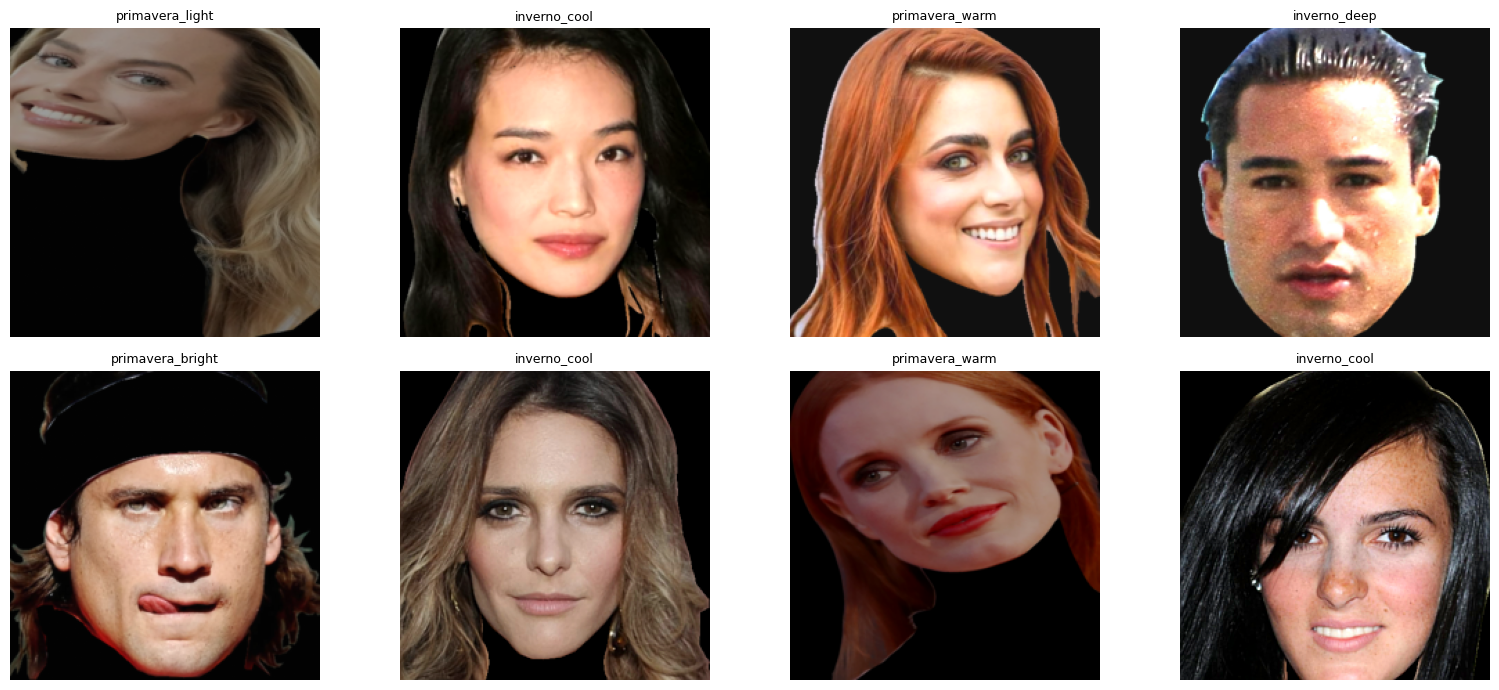

In [16]:
# ============================================================
# 15. VISUAL SANITY CHECK
# ============================================================

def denormalize_clip(x):
    mean = torch.tensor(
        CLIP_MEAN
    ).view(3, 1, 1)

    std = torch.tensor(
        CLIP_STD
    ).view(3, 1, 1)

    return (
        x.cpu() * std + mean
    ).clamp(0, 1)


sample_images, sample_labels = next(
    iter(train_loader)
)

n_show = min(
    8,
    len(sample_images),
)

plt.figure(
    figsize=(16, 7)
)

for i in range(n_show):
    plt.subplot(
        2,
        4,
        i + 1,
    )

    img = (
        denormalize_clip(
            sample_images[i]
        )
        .permute(1, 2, 0)
        .numpy()
    )

    plt.imshow(img)

    plt.title(
        idx2class[
            int(sample_labels[i])
        ],
        fontsize=9,
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

# 16. Build FaRL16 frozen feature extractor

Official FaRL uses CLIP ViT-B/16 architecture.

Notebook mencoba membangun model langsung dari FaRL state dict. Jika versi package tidak mendukung cara itu, fallback mengikuti contoh official FaRL:
1. load CLIP ViT-B/16;
2. load FaRL `state_dict` dengan `strict=False`.

Setelah itu hanya **visual encoder** yang dipertahankan dan seluruh parameternya dibekukan.

In [17]:
# ============================================================
# 16. LOAD FARL16 VISUAL BACKBONE
# ============================================================

farl_obj = torch.load(
    FARL_CKPT,
    map_location="cpu",
)

if (
    isinstance(farl_obj, dict)
    and "state_dict"
    in farl_obj
):
    farl_state = farl_obj[
        "state_dict"
    ]
else:
    farl_state = farl_obj

# Remove possible DistributedDataParallel prefix
farl_state = {
    (
        k[len("module."):]
        if k.startswith("module.")
        else k
    ): v
    for k, v
    in farl_state.items()
}

build_method = None

try:
    farl_clip_model = (
        clip.model.build_model(
            farl_state
        )
    )

    build_method = (
        "clip.model.build_model("
        "FaRL state_dict)"
    )

except Exception as direct_error:
    print(
        "Direct build failed, "
        "using official fallback..."
    )
    print(
        type(direct_error).__name__
    )

    farl_clip_model, _ = (
        clip.load(
            "ViT-B/16",
            device="cpu",
            jit=False,
        )
    )

    incompatible = (
        farl_clip_model
        .load_state_dict(
            farl_state,
            strict=False,
        )
    )

    print(
        "Missing keys:",
        len(
            incompatible.missing_keys
        ),
    )

    print(
        "Unexpected keys:",
        len(
            incompatible.unexpected_keys
        ),
    )

    build_method = (
        "clip.load(ViT-B/16) "
        "+ FaRL load_state_dict"
    )

visual_backbone = (
    farl_clip_model.visual
)

del farl_clip_model
del farl_obj
del farl_state

for p in (
    visual_backbone
    .parameters()
):
    p.requires_grad = False

visual_backbone.eval()

feature_dim = int(
    visual_backbone.output_dim
)

print(
    "FaRL load method:",
    build_method,
)
print(
    "Visual feature dim:",
    feature_dim,
)

assert feature_dim > 0

Direct build failed, using official fallback...
RuntimeError


100%|████████████████████████████████████████| 335M/335M [00:03<00:00, 102MiB/s]


Missing keys: 0
Unexpected keys: 17
FaRL load method: clip.load(ViT-B/16) + FaRL load_state_dict
Visual feature dim: 512


## 17. Paper classifier

Classifier sesuai deskripsi paper:

`FaRL feature D → FC(D/2) → ReLU → Dropout(0.5) → FC(12)`

In [18]:
# ============================================================
# 17. FARL16 + PAPER CLASSIFIER
# ============================================================

class FrozenFaRLClassifier(
    nn.Module
):
    def __init__(
        self,
        visual,
        feature_dim,
        num_classes,
    ):
        super().__init__()

        self.visual = visual

        for p in (
            self.visual
            .parameters()
        ):
            p.requires_grad = False

        hidden_dim = (
            feature_dim // 2
        )

        self.classifier = (
            nn.Sequential(
                nn.Linear(
                    feature_dim,
                    hidden_dim,
                ),
                nn.ReLU(
                    inplace=True
                ),
                nn.Dropout(
                    p=DROPOUT
                ),
                nn.Linear(
                    hidden_dim,
                    num_classes,
                ),
            )
        )

    def train(
        self,
        mode=True,
    ):
        super().train(mode)

        # Backbone paper = frozen feature extractor.
        # Keep it in eval mode even while
        # classifier is training.
        self.visual.eval()

        return self

    def forward(
        self,
        images,
    ):
        # OpenAI CLIP/FaRL visual may
        # use fp16 parameters.
        visual_dtype = (
            self.visual
            .conv1
            .weight
            .dtype
        )

        images = images.to(
            dtype=visual_dtype
        )

        with torch.no_grad():
            features = self.visual(
                images
            )

        # classifier remains float32
        features = features.float()

        logits = self.classifier(
            features
        )

        return logits


model = FrozenFaRLClassifier(
    visual=visual_backbone,
    feature_dim=feature_dim,
    num_classes=NUM_CLASSES,
).to(DEVICE)

total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(
    "Total params    :",
    f"{total_params:,}",
)
print(
    "Trainable params:",
    f"{trainable_params:,}",
)
print(
    "Classifier:"
)
print(model.classifier)

assert all(
    not p.requires_grad
    for p in (
        model.visual
        .parameters()
    )
)

assert any(
    p.requires_grad
    for p in (
        model.classifier
        .parameters()
    )
)

Total params    : 86,327,052
Trainable params: 134,412
Classifier:
Sequential(
  (0): Linear(in_features=512, out_features=256, bias=True)
  (1): ReLU(inplace=True)
  (2): Dropout(p=0.5, inplace=False)
  (3): Linear(in_features=256, out_features=12, bias=True)
)


## 18. GPU forward sanity check

In [19]:
# ============================================================
# 18. FORWARD SANITY CHECK
# ============================================================

model.eval()

sanity_images, sanity_labels = next(
    iter(train_loader)
)

sanity_images = (
    sanity_images
    .to(
        DEVICE,
        non_blocking=True,
    )
)

with torch.no_grad():
    sanity_logits = model(
        sanity_images
    )

print(
    "Input :",
    sanity_images.shape
)
print(
    "Output:",
    sanity_logits.shape
)

assert (
    sanity_logits.shape[1]
    == NUM_CLASSES
)

assert torch.isfinite(
    sanity_logits
).all()

print(
    "✅ FaRL16 forward PASS."
)

Input : torch.Size([64, 3, 224, 224])
Output: torch.Size([64, 12])
✅ FaRL16 forward PASS.


## 19. Optimizer & scheduler — paper setting

- CrossEntropyLoss
- AdamW `lr=1e-3`, `weight_decay=1e-5`
- CosineAnnealingWarmRestarts:
  - `T_0=10`
  - `eta_min=1e-5`

Hanya classifier yang diberikan ke optimizer.

In [20]:
# ============================================================
# 19. LOSS / OPTIMIZER / SCHEDULER
# ============================================================

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.classifier.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

scheduler = (
    torch.optim.lr_scheduler
    .CosineAnnealingWarmRestarts(
        optimizer,
        T_0=WARM_RESTART_T0,
        T_mult=1,
        eta_min=MIN_LR,
    )
)

print(optimizer)
print(scheduler)

AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    initial_lr: 0.001
    lr: 0.001
    maximize: False
    weight_decay: 1e-05
)


## 20. Training utilities

In [21]:
# ============================================================
# 20. TRAINING UTILITIES
# ============================================================

def train_one_epoch(
    model,
    loader,
    optimizer,
    criterion,
):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, targets in loader:
        images = images.to(
            DEVICE,
            non_blocking=True,
        )

        targets = targets.to(
            DEVICE,
            non_blocking=True,
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        logits = model(
            images
        )

        loss = criterion(
            logits,
            targets
        )

        loss.backward()
        optimizer.step()

        batch_size = (
            images.size(0)
        )

        running_loss += (
            loss.item()
            * batch_size
        )

        preds = (
            logits.argmax(dim=1)
        )

        correct += int(
            (
                preds == targets
            )
            .sum()
            .item()
        )

        total += batch_size

    return {
        "loss": (
            running_loss / total
        ),
        "accuracy": (
            correct / total
        ),
    }

# 21. Train exactly 50 epochs

Tidak ada:
- validation tuning,
- early stopping,
- class weighting,
- label smoothing,
- hierarchical auxiliary head,
- confidence fusion.

Tujuan E5 adalah membuat **paper-style FaRL16 baseline** terlebih dahulu.

In [22]:
# ============================================================
# 21. FIXED 50-EPOCH TRAINING
# ============================================================

history = []

training_start = time.time()

for epoch in range(
    1,
    EPOCHS + 1,
):
    epoch_start = time.time()

    metrics = train_one_epoch(
        model,
        train_loader,
        optimizer,
        criterion,
    )

    # Paper says warm restart every 10.
    # Operational interpretation:
    # scheduler advances once per epoch.
    scheduler.step(epoch)

    elapsed = (
        time.time()
        - epoch_start
    )

    current_lr = (
        optimizer
        .param_groups[0]["lr"]
    )

    row = {
        "epoch": epoch,
        "train_loss": metrics[
            "loss"
        ],
        "train_accuracy": metrics[
            "accuracy"
        ],
        "lr": current_lr,
        "seconds": elapsed,
    }

    history.append(row)

    print(
        f"Epoch "
        f"{epoch:02d}/{EPOCHS} | "
        f"{elapsed:6.1f}s | "
        f"loss "
        f"{metrics['loss']:.4f} | "
        f"acc "
        f"{metrics['accuracy']:.4f} | "
        f"lr "
        f"{current_lr:.2e}"
    )

training_seconds = (
    time.time()
    - training_start
)

print(
    "\nTraining finished in:",
    f"{training_seconds/60:.2f} min",
)

Epoch 01/50 |   44.3s | loss 2.1018 | acc 0.2732 | lr 9.76e-04
Epoch 02/50 |   47.7s | loss 1.7312 | acc 0.3925 | lr 9.05e-04
Epoch 03/50 |   52.2s | loss 1.5892 | acc 0.4523 | lr 7.96e-04
Epoch 04/50 |   50.3s | loss 1.5206 | acc 0.4755 | lr 6.58e-04
Epoch 05/50 |   51.4s | loss 1.4817 | acc 0.4868 | lr 5.05e-04
Epoch 06/50 |   51.3s | loss 1.4191 | acc 0.5110 | lr 3.52e-04
Epoch 07/50 |   50.8s | loss 1.4027 | acc 0.5227 | lr 2.14e-04
Epoch 08/50 |   51.5s | loss 1.3742 | acc 0.5334 | lr 1.05e-04
Epoch 09/50 |   50.9s | loss 1.3535 | acc 0.5329 | lr 3.42e-05
Epoch 10/50 |   50.9s | loss 1.3448 | acc 0.5374 | lr 1.00e-03
Epoch 11/50 |   51.3s | loss 1.3828 | acc 0.5212 | lr 9.76e-04
Epoch 12/50 |   51.9s | loss 1.3612 | acc 0.5299 | lr 9.05e-04
Epoch 13/50 |   51.1s | loss 1.3305 | acc 0.5427 | lr 7.96e-04
Epoch 14/50 |   50.9s | loss 1.2740 | acc 0.5621 | lr 6.58e-04
Epoch 15/50 |   51.2s | loss 1.2549 | acc 0.5701 | lr 5.05e-04
Epoch 16/50 |   50.8s | loss 1.2379 | acc 0.5776 | lr 3

## 22. Training curves

,epoch,train_loss,train_accuracy,lr,seconds
40,41,0.962178,0.668663,0.000976,51.116104
41,42,0.976263,0.664671,0.000905,50.731268
42,43,0.945007,0.676896,0.000796,51.071890
43,44,0.912380,0.683633,0.000658,51.089639
44,45,0.903556,0.682635,0.000505,50.982325
45,46,0.881683,0.697854,0.000352,51.408094
46,47,0.872136,0.700599,0.000214,50.808135
47,48,0.851347,0.708583,0.000105,51.228701
48,49,0.823194,0.720559,0.000034,51.023219
49,50,0.826069,0.719062,0.001000,51.191370


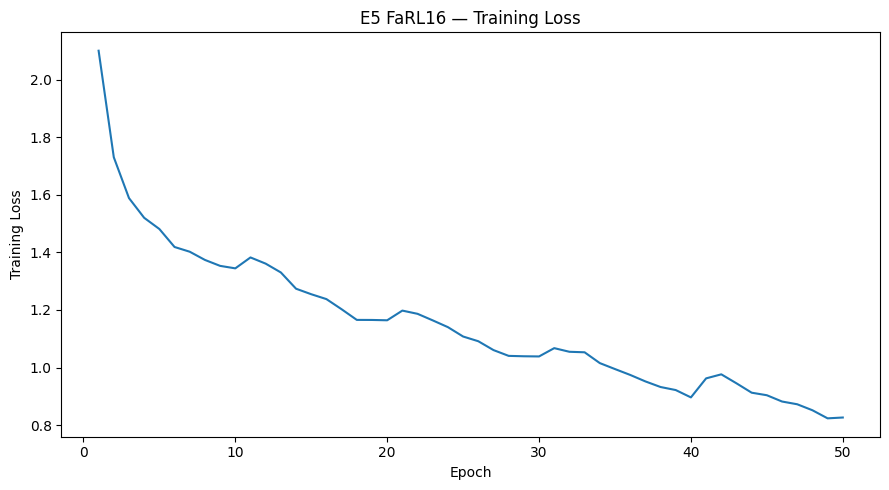

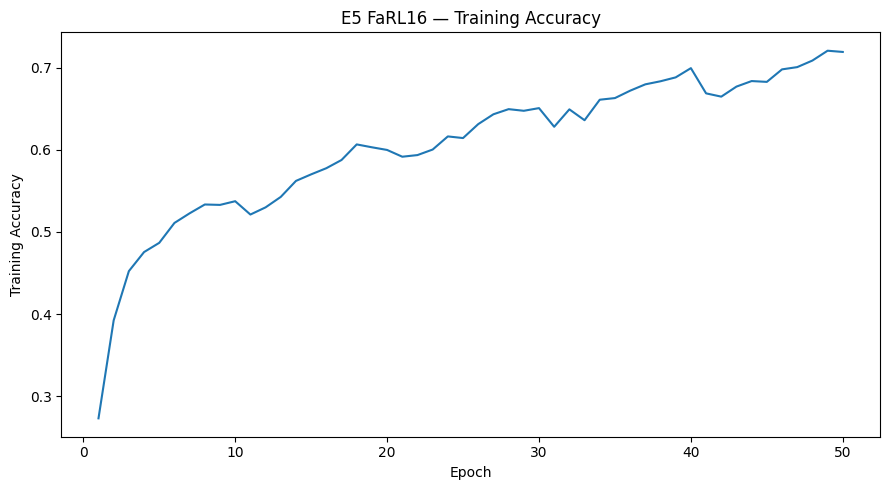

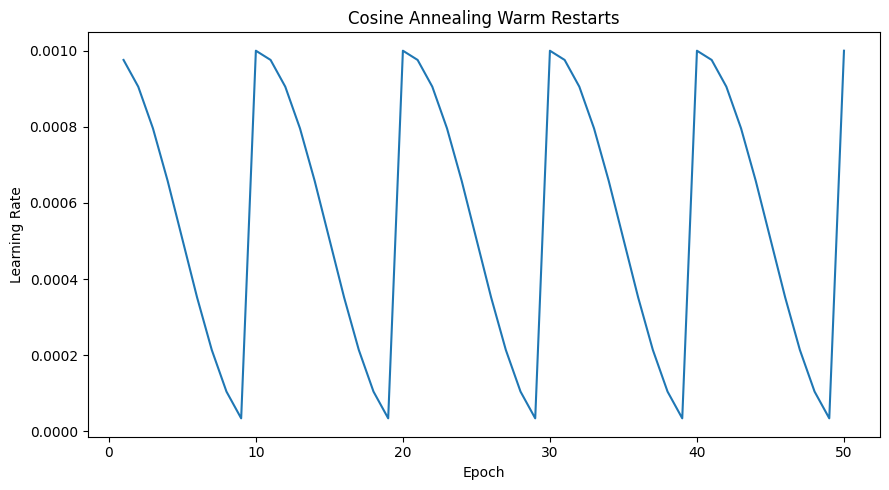

In [23]:
# ============================================================
# 22. TRAINING CURVES
# ============================================================

history_df = pd.DataFrame(
    history
)

HISTORY_PATH = Path(
    "/kaggle/working/"
    "E5_FaRL16_training_history.csv"
)

history_df.to_csv(
    HISTORY_PATH,
    index=False,
)

display(
    history_df.tail(10)
)

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title(
    "E5 FaRL16 — Training Loss"
)
plt.tight_layout()
plt.show()

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    history_df["epoch"],
    history_df[
        "train_accuracy"
    ],
)

plt.xlabel("Epoch")
plt.ylabel("Training Accuracy")
plt.title(
    "E5 FaRL16 — Training Accuracy"
)
plt.tight_layout()
plt.show()

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    history_df["epoch"],
    history_df["lr"],
)

plt.xlabel("Epoch")
plt.ylabel("Learning Rate")
plt.title(
    "Cosine Annealing "
    "Warm Restarts"
)
plt.tight_layout()
plt.show()

# 23. Official test — final evaluation

Official test baru dipakai setelah semua 50 training epoch selesai.

Paper tidak menjelaskan averaging mode untuk precision/recall/F1 pada potongan metodologi yang tersedia. Karena itu notebook melaporkan:

- Macro Precision / Recall / F1
- Weighted Precision / Recall / F1
- Accuracy
- Top-3 Accuracy

Benchmark paper tetap ditampilkan sebagai angka yang dilaporkan paper, tanpa mengasumsikan averaging convention.

In [24]:
# ============================================================
# 23. COLLECT OFFICIAL TEST OUTPUTS
# ============================================================

@torch.no_grad()
def collect_test_outputs(
    model,
    loader,
):
    model.eval()

    y_true = []
    y_pred = []
    probs_list = []

    total_loss = 0.0
    total = 0

    for images, targets in loader:
        images = images.to(
            DEVICE,
            non_blocking=True,
        )

        targets = targets.to(
            DEVICE,
            non_blocking=True,
        )

        logits = model(
            images
        )

        loss = criterion(
            logits,
            targets
        )

        probs = torch.softmax(
            logits,
            dim=1
        )

        preds = probs.argmax(
            dim=1
        )

        batch_size = (
            images.size(0)
        )

        total_loss += (
            loss.item()
            * batch_size
        )

        total += batch_size

        y_true.extend(
            targets
            .cpu()
            .tolist()
        )

        y_pred.extend(
            preds
            .cpu()
            .tolist()
        )

        probs_list.append(
            probs.cpu()
        )

    return (
        np.array(y_true),
        np.array(y_pred),
        torch.cat(
            probs_list,
            dim=0,
        ).numpy(),
        total_loss / total,
    )


(
    y_true,
    y_pred,
    y_probs,
    test_loss,
) = collect_test_outputs(
    model,
    test_loader,
)

print(
    "Official test samples:",
    len(y_true),
)

Official test samples: 912


In [25]:
# ============================================================
# 24. OFFICIAL TEST METRICS
# ============================================================

accuracy = accuracy_score(
    y_true,
    y_pred,
)

(
    macro_precision,
    macro_recall,
    macro_f1,
    _,
) = precision_recall_fscore_support(
    y_true,
    y_pred,
    average="macro",
    zero_division=0,
)

(
    weighted_precision,
    weighted_recall,
    weighted_f1,
    _,
) = precision_recall_fscore_support(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0,
)

top3_indices = np.argsort(
    y_probs,
    axis=1,
)[:, -3:]

top3_accuracy = float(
    np.mean([
        true_label in row
        for true_label, row
        in zip(
            y_true,
            top3_indices,
        )
    ])
)

final_metrics = {
    "test_loss": float(
        test_loss
    ),
    "accuracy": float(
        accuracy
    ),
    "macro_precision": float(
        macro_precision
    ),
    "macro_recall": float(
        macro_recall
    ),
    "macro_f1": float(
        macro_f1
    ),
    "weighted_precision": float(
        weighted_precision
    ),
    "weighted_recall": float(
        weighted_recall
    ),
    "weighted_f1": float(
        weighted_f1
    ),
    "top3_accuracy": float(
        top3_accuracy
    ),
}

print("=" * 72)
print(
    "E5 FARL16 — OFFICIAL TEST"
)
print("=" * 72)

for key, value in (
    final_metrics.items()
):
    print(
        f"{key:20s}: "
        f"{value:.4f}"
    )

E5 FARL16 — OFFICIAL TEST
test_loss           : 2.1785
accuracy            : 0.2982
macro_precision     : 0.2803
macro_recall        : 0.2780
macro_f1            : 0.2741
weighted_precision  : 0.2974
weighted_recall     : 0.2982
weighted_f1         : 0.2933
top3_accuracy       : 0.6425


## 25. Classification report & per-class recall

In [26]:
# ============================================================
# 25. CLASSIFICATION REPORT
# ============================================================

report_dict = (
    classification_report(
        y_true,
        y_pred,
        labels=list(
            range(NUM_CLASSES)
        ),
        target_names=class_names,
        output_dict=True,
        zero_division=0,
    )
)

report_df = pd.DataFrame(
    report_dict
).T

per_class_df = (
    report_df
    .loc[
        class_names,
        [
            "precision",
            "recall",
            "f1-score",
            "support",
        ],
    ]
    .copy()
)

display(
    per_class_df
    .sort_values(
        "recall",
        ascending=False,
    )
)

REPORT_PATH = Path(
    "/kaggle/working/"
    "E5_FaRL16_classification_report.csv"
)

report_df.to_csv(
    REPORT_PATH
)

,precision,recall,f1-score,support
autunno_deep,0.414286,0.517857,0.460317,112.0
inverno_deep,0.444444,0.410256,0.426667,117.0
estate_light,0.294118,0.357143,0.322581,70.0
primavera_light,0.278481,0.343750,0.307692,64.0
inverno_cool,0.282609,0.292135,0.287293,89.0
estate_cool,0.180723,0.283019,0.220588,53.0
autunno_warm,0.317460,0.270270,0.291971,74.0
primavera_warm,0.271186,0.219178,0.242424,73.0
autunno_soft,0.182927,0.205479,0.193548,73.0
inverno_bright,0.314286,0.189655,0.236559,58.0


## 26. Confusion matrix

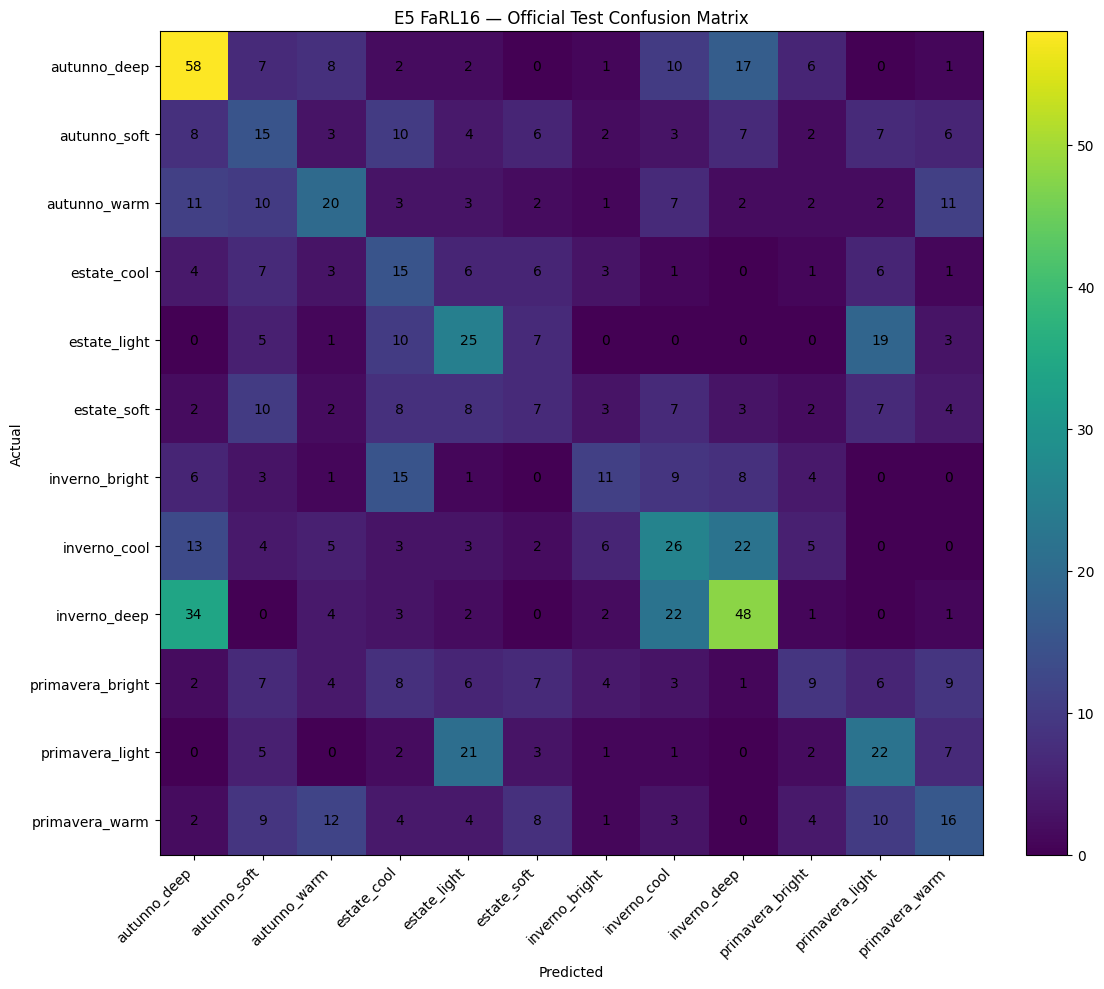

In [27]:
# ============================================================
# 26. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(
        range(NUM_CLASSES)
    ),
)

fig, ax = plt.subplots(
    figsize=(12, 10)
)

im = ax.imshow(cm)

ax.set_xticks(
    np.arange(NUM_CLASSES)
)
ax.set_yticks(
    np.arange(NUM_CLASSES)
)

ax.set_xticklabels(
    class_names,
    rotation=45,
    ha="right",
)
ax.set_yticklabels(
    class_names,
)

ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")

ax.set_title(
    "E5 FaRL16 — "
    "Official Test Confusion Matrix"
)

for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center",
        )

fig.colorbar(
    im,
    ax=ax,
    fraction=0.046,
    pad=0.04,
)

plt.tight_layout()

CM_PATH = Path(
    "/kaggle/working/"
    "E5_FaRL16_confusion_matrix.png"
)

plt.savefig(
    CM_PATH,
    dpi=160,
    bbox_inches="tight",
)

plt.show()

## 27. Diagnostic derived 4-season accuracy

Ini **bukan** benchmark 4-class paper.  
Prediksi 12-class hanya diagregasikan kembali ke season untuk memahami jenis error.

In [28]:
# ============================================================
# 27. DERIVED 4-SEASON DIAGNOSTIC
# ============================================================

def joint_to_season(
    joint_name
):
    return joint_name.split(
        "_",
        1,
    )[0]


season_true = np.array([
    joint_to_season(
        idx2class[int(i)]
    )
    for i in y_true
])

season_pred = np.array([
    joint_to_season(
        idx2class[int(i)]
    )
    for i in y_pred
])

derived_season_accuracy = float(
    np.mean(
        season_true
        == season_pred
    )
)

print(
    "Derived season accuracy:",
    f"{derived_season_accuracy:.4f}",
)

print(
    "Diagnostic only — "
    "bukan direct 4-class model."
)

Derived season accuracy: 0.5164
Diagnostic only — bukan direct 4-class model.


## 28. Compare E5 vs project EfficientNet & paper FaRL16

In [29]:
# ============================================================
# 28. BENCHMARK COMPARISON
# ============================================================

comparison_df = pd.DataFrame([
    {
        "metric": "Accuracy",
        "Project EfficientNet Best":
            PROJECT_EFFICIENTNET_BEST[
                "accuracy"
            ],
        "E5 FaRL16":
            final_metrics[
                "accuracy"
            ],
        "Paper FaRL16":
            PAPER_FARL16[
                "accuracy"
            ],
    },
    {
        "metric": "Macro Recall",
        "Project EfficientNet Best":
            PROJECT_EFFICIENTNET_BEST[
                "macro_recall"
            ],
        "E5 FaRL16":
            final_metrics[
                "macro_recall"
            ],
        "Paper FaRL16":
            PAPER_FARL16[
                "recall"
            ],
    },
    {
        "metric": "Macro F1",
        "Project EfficientNet Best":
            PROJECT_EFFICIENTNET_BEST[
                "macro_f1"
            ],
        "E5 FaRL16":
            final_metrics[
                "macro_f1"
            ],
        "Paper FaRL16":
            PAPER_FARL16[
                "f1"
            ],
    },
    {
        "metric": "Top-3",
        "Project EfficientNet Best":
            PROJECT_EFFICIENTNET_BEST[
                "top3_accuracy"
            ],
        "E5 FaRL16":
            final_metrics[
                "top3_accuracy"
            ],
        "Paper FaRL16":
            PAPER_FARL16[
                "top3_accuracy"
            ],
    },
])

comparison_df[
    "E5 vs EfficientNet (pp)"
] = (
    comparison_df["E5 FaRL16"]
    - comparison_df[
        "Project EfficientNet Best"
    ]
) * 100

comparison_df[
    "E5 vs Paper (pp)"
] = (
    comparison_df["E5 FaRL16"]
    - comparison_df[
        "Paper FaRL16"
    ]
) * 100

display(
    comparison_df.style.format({
        "Project EfficientNet Best":
            "{:.4f}",
        "E5 FaRL16":
            "{:.4f}",
        "Paper FaRL16":
            "{:.4f}",
        "E5 vs EfficientNet (pp)":
            "{:+.2f}",
        "E5 vs Paper (pp)":
            "{:+.2f}",
    })
)

if (
    final_metrics["accuracy"]
    > PAPER_FARL16["accuracy"]
):
    print(
        "✅ E5 point-estimate accuracy "
        "melampaui paper FaRL16."
    )
else:
    gap = (
        PAPER_FARL16["accuracy"]
        - final_metrics["accuracy"]
    ) * 100

    print(
        "E5 belum melampaui "
        "paper FaRL16. Gap:",
        f"{gap:.2f} pp"
    )

,metric,Project EfficientNet Best,E5 FaRL16,Paper FaRL16,E5 vs EfficientNet (pp),E5 vs Paper (pp)
0,Accuracy,0.3059,0.2982,0.3180,-0.77,-1.98
1,Macro Recall,0.2809,0.2780,0.3180,-0.29,-4.00
2,Macro F1,0.2700,0.2741,0.3100,+0.41,-3.59
3,Top-3,0.6349,0.6425,0.6630,+0.76,-2.05


E5 belum melampaui paper FaRL16. Gap: 1.98 pp


## 29. Save artifacts

Karena backbone FaRL16 frozen dan checkpoint official tersedia terpisah, notebook menyimpan **classifier head** + metadata saja. Ini jauh lebih kecil daripada menduplikasiasikan seluruh FaRL checkpoint.

In [30]:
# ============================================================
# 29. SAVE ARTIFACTS
# ============================================================

CLASSIFIER_PATH = Path(
    "/kaggle/working/"
    "E5_FaRL16_armocromia_classifier.pth"
)

torch.save(
    {
        "experiment_id":
            EXPERIMENT_ID,
        "classifier_state_dict":
            model.classifier
            .state_dict(),
        "feature_dim":
            feature_dim,
        "num_classes":
            NUM_CLASSES,
        "class2idx":
            class2idx,
        "idx2class":
            idx2class,
        "farl_checkpoint":
            FARL_FILENAME,
        "img_size":
            IMG_SIZE,
        "clip_mean":
            CLIP_MEAN,
        "clip_std":
            CLIP_STD,
        "final_metrics":
            final_metrics,
    },
    CLASSIFIER_PATH,
)

METRICS_PATH = Path(
    "/kaggle/working/"
    "E5_FaRL16_final_metrics.json"
)

payload = {
    "experiment_id":
        EXPERIMENT_ID,
    "experiment_name":
        EXPERIMENT_NAME,
    "official_train_size":
        len(train_df),
    "official_test_size":
        len(test_df),
    "epochs":
        EPOCHS,
    "batch_size":
        BATCH_SIZE,
    "learning_rate":
        LEARNING_RATE,
    "weight_decay":
        WEIGHT_DECAY,
    "warm_restart_t0":
        WARM_RESTART_T0,
    "min_lr":
        MIN_LR,
    "dropout":
        DROPOUT,
    "feature_dim":
        feature_dim,
    "training_minutes":
        training_seconds / 60,
    "metrics":
        final_metrics,
    "derived_season_accuracy":
        derived_season_accuracy,
}

with open(
    METRICS_PATH,
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        payload,
        f,
        indent=2,
    )

print("Saved artifacts:")
for path in [
    CLASSIFIER_PATH,
    HISTORY_PATH,
    REPORT_PATH,
    CM_PATH,
    METRICS_PATH,
]:
    print("-", path)

print(
    "\n✅ E5 FaRL16 "
    "paper-replication complete."
)

Saved artifacts:
- /kaggle/working/E5_FaRL16_armocromia_classifier.pth
- /kaggle/working/E5_FaRL16_training_history.csv
- /kaggle/working/E5_FaRL16_classification_report.csv
- /kaggle/working/E5_FaRL16_confusion_matrix.png
- /kaggle/working/E5_FaRL16_final_metrics.json

✅ E5 FaRL16 paper-replication complete.


## 30. Inference helper untuk satu RGB-M image

Fungsi ini mengharapkan **RGB-M / masked RGB image**, bukan raw selfie.

Pipeline platform raw selfie tetap memerlukan face parsing/masking yang kompatibel dengan preprocessing dataset.

In [31]:
# ============================================================
# 30. SINGLE-IMAGE RGB-M INFERENCE
# ============================================================

@torch.no_grad()
def predict_rgbm_pil(
    pil_image,
    top_k=3,
):
    model.eval()

    image = (
        test_transform(
            pil_image.convert("RGB")
        )
        .unsqueeze(0)
        .to(DEVICE)
    )

    logits = model(image)

    probs = torch.softmax(
        logits,
        dim=1,
    )[0]

    values, indices = torch.topk(
        probs,
        k=min(
            top_k,
            NUM_CLASSES,
        ),
    )

    results = []

    for prob, idx in zip(
        values.cpu().tolist(),
        indices.cpu().tolist(),
    ):
        results.append({
            "class":
                idx2class[int(idx)],
            "probability":
                float(prob),
        })

    return results


print(
    "Inference helper ready."
)

Inference helper ready.


# Interpretasi E5

E5 memiliki satu tujuan: **menguji apakah backbone face-specific FaRL16 dengan recipe paper benar-benar lebih cocok daripada EfficientNet-B0 pada dataset ini**.

Jangan mengubah hyperparameter E5 sebelum run pertama selesai.

Setelah hasil keluar, bandingkan:

1. Accuracy official test.
2. Macro/Weighted F1.
3. Top-3 Accuracy.
4. Per-class recall.
5. Confusion pattern:
   - Autumn Deep ↔ Winter Deep
   - Summer Cool ↔ Winter Cool
   - Spring Bright ↔ Spring Light / Spring Warm

Jika E5 mendekati atau melampaui benchmark paper, tahap berikutnya dapat menjadi:

- **E6: FaRL16 + auxiliary 4-season head**, atau
- **E7: true hierarchical Season → valid subtype**, atau
- controlled partial unfreeze 1–2 transformer blocks dengan LR sangat kecil.

Namun E5 harus tetap menjadi baseline paper-style yang sederhana dan dapat direproduksi.

In [32]:
import modellab_registry

# 1. Ekstrak hasil evaluasi yang sudah dihitung oleh notebook di sel sebelumnya
accuracy = final_metrics["accuracy"]
f1_score = final_metrics["macro_f1"]
precision = final_metrics["macro_precision"]
recall = final_metrics["macro_recall"]

# 2. Panggil fungsi auto-log, sertakan globals() dan panggil variabel konfigurasi master
modellab_registry.auto_log_experiment(
    env_globals=globals(),
    topic="topic-a",
    model="FaRL16",
    objective="Replikasi Paper Deep Armocromia",
    dataset="deep_armocromia",
    owner="Fatih Itsbatul Haq"
)

===REGISTRY_PAYLOAD_START===
{"topic": "topic-a", "model": "FaRL16", "objective": "Replikasi Paper Deep Armocromia", "dataset": "deep_armocromia", "owner": "Fatih Itsbatul Haq", "metrics": {"accuracy": 0.2982456140350877, "f1": 0.2740703128533433, "precision": 0.28026626216286926, "recall": 0.2780181528372499}}
===REGISTRY_PAYLOAD_END===
